## ENEM: Rede Neural

-> A rede é o `MLPRegressor` da statstech: uma rede com camadas ReLU treinada por gradiente descendente em mini-lotes por um número fixo de épocas.

#### 0. Configuração inicial

In [8]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
from statstech.linear_model import Ridge
from statstech.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_score,
    train_test_split,
)
from statstech.neural_network import MLPRegressor
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import SEED, STYLE, TABLES
from analysis.evaluation import evaluate_regressor
from analysis.io import load_dataset
from analysis.report import save_figure, save_table

plt.style.use(STYLE)


def make_pipeline(model):
    # Padroniza X dentro de cada ajuste; o y é padronizado pela própria rede (scale_y).
    return Pipeline([("scaler", StandardScaler()), ("model", model)])


def rmse(y_true, y_pred):
    return evaluate_regressor(y_true, y_pred)["rmse"]

#### 1. Dados

In [9]:
data = load_dataset("enem")
X_train, y_train = data["X_train"], data["y_train"]
feature_names = data["feature_names"].tolist()

print(f"treino: {X_train.shape[0]} participantes, {X_train.shape[1]} colunas")
print(f"nota média: {y_train.mean():.1f} pontos, desvio padrão {y_train.std():.1f}")

treino: 38347 participantes, 41 colunas
nota média: 545.2 pontos, desvio padrão 87.7


#### 2. Validação

Temos duas formas de separar o treino: Cross Validation ou divisão fixa do terino em 80% e 20% por exemplo. 
O cv (cross validation) escolhe e compara já a divisão fixa auxiliaria em diagnósticos rápidos. 

In [10]:
cv = KFold(5, shuffle=True, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              random_state=SEED)
print(f"diagnóstico: {len(y_fit)} para ajustar, {len(y_val)} para validar")

diagnóstico: 30677 para ajustar, 7670 para validar


#### 3. Baselines: Média e Ridge

Para podermos comparar os resultados da rede neural com outros modelos, por exemplo, a média e o Ridge (melhor modelo linear)

In [11]:
mean_scores = []
for fit_idx, val_idx in cv.split(X_train):
    prediction = np.full(len(val_idx), y_train[fit_idx].mean())
    mean_scores.append(rmse(y_train[val_idx], prediction))
mean_scores = np.array(mean_scores)

ridge_search = GridSearchCV(make_pipeline(Ridge()),
                            {"model__alpha": list(np.logspace(-2, 4, 13))},
                            cv=cv, scoring="rmse").fit(X_train, y_train)
ridge_best = ridge_search.cv_results_[ridge_search.best_index_]
#TODO conferir com o resultado da regularização usando o Ridge

print(f"média do treino   RMSE {mean_scores.mean():.2f} ± {mean_scores.std(ddof=1):.2f}")
print(f"Ridge (alpha={ridge_search.best_params_['model__alpha']:.3g})  "
      f"RMSE {ridge_best['mean_score']:.2f} ± {ridge_best['std_score']:.2f}")

média do treino   RMSE 87.74 ± 0.61
Ridge (alpha=316)  RMSE 72.87 ± 0.83


#### 4. Teste inicial 

Antes da busca, podemos inicialmente fazer um simples teste para observar se a rede aprende e medir quanto tempo a busca vai levar. 

In [12]:
first = make_pipeline(MLPRegressor(hidden_layer_sizes=(64, 32), learning_rate=1e-3,
                                   max_iter=200, batch_size=64, random_state=SEED,
                                   scale_y=True))
start = time.perf_counter()
first.fit(X_fit, y_fit)
seconds_per_epoch = (time.perf_counter() - start) / 200

ridge_holdout = make_pipeline(Ridge(alpha=ridge_search.best_params_["model__alpha"]))
ridge_holdout.fit(X_fit, y_fit)

print(f"tempo: {seconds_per_epoch:.2f} s por época com {len(y_fit)} linhas")
print(f"RMSE da rede:  treino {rmse(y_fit, first.predict(X_fit)):.2f}   "
      f"validação {rmse(y_val, first.predict(X_val)):.2f}")
print(f"RMSE da Ridge: treino {rmse(y_fit, ridge_holdout.predict(X_fit)):.2f}   "
      f"validação {rmse(y_val, ridge_holdout.predict(X_val)):.2f}")

tempo: 0.11 s por época com 30677 linhas
RMSE da rede:  treino 71.57   validação 72.60
RMSE da Ridge: treino 72.86   validação 72.61


#### 5. Número de Épocas

Analisar o resultado do RMSE no treino e na validação.

In [13]:
epoch_grid = [25, 50, 100, 200]
curves = {}
holdout = {}
print("learning_rate  épocas  RMSE treino  RMSE validação")
for lr in [1e-3, 1e-2]:
    for epochs in epoch_grid:
        model = make_pipeline(MLPRegressor(hidden_layer_sizes=(64, 32), learning_rate=lr,
                                           max_iter=epochs, batch_size=64,
                                           random_state=SEED, scale_y=True))
        model.fit(X_fit, y_fit)
        holdout[lr, epochs] = (rmse(y_fit, model.predict(X_fit)),
                               rmse(y_val, model.predict(X_val)))
        print(f"{lr:13g}  {epochs:6d}  {holdout[lr, epochs][0]:11.2f}  "
              f"{holdout[lr, epochs][1]:14.2f}")
    curves[lr] = model.named_steps_["model"].loss_curve_  # a de 200 épocas

learning_rate  épocas  RMSE treino  RMSE validação
        0.001      25        73.06           73.14
        0.001      50        72.54           72.85
        0.001     100        72.11           72.69
        0.001     200        71.57           72.60
         0.01      25        71.65           72.74
         0.01      50        70.93           72.92
         0.01     100        69.89           73.28
         0.01     200        69.03           74.09


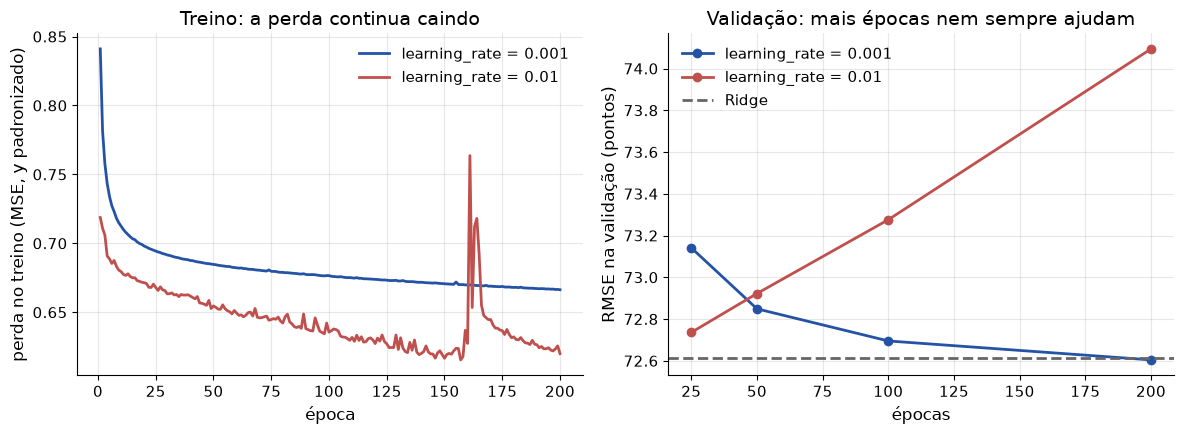

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for lr, curve in curves.items():
    axes[0].plot(np.arange(1, len(curve) + 1), curve, label=f"learning_rate = {lr:g}")
    axes[1].plot(epoch_grid, [holdout[lr, e][1] for e in epoch_grid], marker="o",
                 label=f"learning_rate = {lr:g}")
axes[1].axhline(rmse(y_val, ridge_holdout.predict(X_val)), color="0.4", ls="--",
                label="Ridge")
axes[0].set_xlabel("época")
axes[0].set_ylabel("perda no treino (MSE, y padronizado)")
axes[0].set_title("Treino")
axes[1].set_xlabel("épocas")
axes[1].set_ylabel("RMSE na validação (pontos)")
axes[1].set_title("Validação")
for ax in axes:
    ax.legend()
fig.tight_layout()
save_figure(fig, "enem_rede_perda")
plt.show()

Com passo 0,001, treino e validação caem juntos até 200 épocas, sem sobreajuste. Com passo 0,01, o RMSE de treino continua caindo, mas o de validação sobe depois de 25 épocas: a rede começa a decorar o treino.

Por isso o número de épocas (`max_iter`) entra na busca como hiperparâmetro.

#### 6. Busca de Hiperparâmetros



In [15]:
grid = {
    "model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
    "model__learning_rate": [1e-3, 1e-2],
    "model__max_iter": [50, 200],
}
start = time.perf_counter()
search = GridSearchCV(
    make_pipeline(MLPRegressor(batch_size=64, random_state=SEED, scale_y=True)),
    grid, cv=cv, scoring="rmse",
).fit(X_train, y_train)
print(f"busca: {(time.perf_counter() - start) / 60:.1f} minutos\n")

rows = []
for r in search.cv_results_:
    p = r["params"]
    rows.append({"hidden_layer_sizes": str(p["model__hidden_layer_sizes"]),
                 "learning_rate": p["model__learning_rate"],
                 "max_iter": p["model__max_iter"],
                 "rmse": round(r["mean_score"], 3), "rmse_std": round(r["std_score"], 3)})
rows.sort(key=lambda row: row["rmse"])
save_table(rows, "enem_rede_busca")

print("camadas     learning_rate  épocas  RMSE")
for row in rows:
    print(f"{row['hidden_layer_sizes']:11s} {row['learning_rate']:13g}  {row['max_iter']:6d}  "
          f"{row['rmse']:.2f} ± {row['rmse_std']:.2f}")

KeyboardInterrupt: 

##EDITAR Observar os resultados da tabela e escolher por aquele que de certa forma tem um bom resultado mas tem (menos camadas, menos épocas).

#### 7. Treino x Validação

In [ ]:
best_params = search.best_params_
best_model = make_pipeline(MLPRegressor(batch_size=64, random_state=SEED, scale_y=True))
best_model.set_params(**best_params).fit(X_fit, y_fit)
train_rmse = rmse(y_fit, best_model.predict(X_fit))
val_rmse = rmse(y_val, best_model.predict(X_val))
print("melhor:", best_params)
print(f"RMSE treino {train_rmse:.2f}   validação {val_rmse:.2f}   "
      f"diferença {val_rmse - train_rmse:.2f} pontos")

#### 8. Variação entre sementes

Como o resultado depende da semente, vamos analisar 3 sementes diferentes com validação cruzada do melhor modelo.

In [ ]:
seed_rmse = {}
for seed in [SEED, SEED + 1, SEED + 2]:
    model = make_pipeline(MLPRegressor(batch_size=64, random_state=seed, scale_y=True))
    model.set_params(**best_params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="rmse")
    seed_rmse[seed] = scores
    print(f"semente {seed}: RMSE {scores.mean():.2f} ± {scores.std(ddof=1):.2f}")

means = np.array([s.mean() for s in seed_rmse.values()])
print(f"\nmédia das 3 sementes: {means.mean():.2f}   "
      f"variação entre sementes: {means.max() - means.min():.2f} pontos")

#### 9. Rede Neural x Ridge

In [ ]:
table = [
    {"model": "Média do treino", "rmse": mean_scores.mean(),
     "rmse_std": mean_scores.std(ddof=1)},
    {"model": "Ridge", "rmse": ridge_best["mean_score"], "rmse_std": ridge_best["std_score"]},
    {"model": "Rede neural (3 sementes)", "rmse": means.mean(),
     "rmse_std": np.mean([s.std(ddof=1) for s in seed_rmse.values()])},
]
for row in table:
    print(f"{row['model']:26s} RMSE {row['rmse']:.2f} ± {row['rmse_std']:.2f}")
gain = ridge_best["mean_score"] - means.mean()
print(f"\nganho da rede sobre a Ridge: {gain:.2f} pontos de RMSE")
save_table([{k: round(v, 3) if isinstance(v, float) else v for k, v in row.items()}
            for row in table], "enem_rede")

###EDITAR Compare o ganho com o desvio entre folds e com a variação entre sementes. Se o ganho for menor que eles, a rede não é melhor que a Ridge nesta base: as relações entre o contexto e a nota são quase aditivas. A comparação definitiva, com intervalo de confiança para a diferença, fica para a avaliação final no teste.

#### 10. Hiperparâmetros salvos para a avaliação final

In [ ]:
fixed = {"model__batch_size": 64, "model__scale_y": True}
params = {k: list(v) if isinstance(v, tuple) else v for k, v in best_params.items()}
with open(TABLES / "enem_rede_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "fixed": fixed, "params": params,
               "rmse_cv": float(means.mean())}, f, indent=2)
print(params)

#### 11. Conclusão 

EDITAR pelos resultados obtidos no treino